# CIFAR-10 image classification with a CNN from scratch

Final model from a 12-experiment ablation study (architecture depth, batch normalisation, optimiser,
dropout, weight initialisation, activation, dense width). The full experiment log is in
[`../EXPERIMENTS.md`](../EXPERIMENTS.md).

**Final architecture:** 6 conv layers (32-32-64-64-128-128, 3x3, BatchNorm, LeakyReLU, max-pool after
every pair) followed by Dense 256 (dropout 0.3) and Dense 128 (dropout 0.4); He initialisation;
Adam (lr 1e-3, weight decay 5e-4); mixed-precision training with early stopping on validation loss.

## Imports

In [ ]:

!pip -q install torchinfo

from dataclasses import dataclass
from typing import List, Callable, Optional, Tuple

import os
import seaborn as sns
import pandas as pd
import numpy as np
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchinfo import summary

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
%matplotlib inline


## Device

In [ ]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = (DEVICE == "cuda")

print(f"Using device: {DEVICE}")
print(f"Mixed precision (AMP): {use_amp}")

Using device: cuda
Mixed precision (AMP): True


## Data

In [ ]:

class DataManager:
    def __init__(self, dataset_class, root: str = "./data", val_fraction: float = 0.1,
                 batch_size: int = 32, seed: int = 42):
        self.dataset_class = dataset_class
        self.root = root
        self.val_fraction = val_fraction
        self.batch_size = batch_size
        self.seed = seed

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=(0.4914, 0.4822, 0.4465),
                std=(0.2470, 0.2435, 0.2616)
            )
        ])

    def get_loaders(self) -> Tuple[DataLoader, DataLoader, DataLoader]:
        full_train = self.dataset_class(root=self.root, train=True,
                                        download=True, transform=self.transform)
        test_ds = self.dataset_class(root=self.root, train=False,
                                     download=True, transform=self.transform)

        val_size = int(len(full_train) * self.val_fraction)
        train_size = len(full_train) - val_size

        generator = torch.Generator().manual_seed(self.seed)
        train_ds, val_ds = random_split(full_train, [train_size, val_size], generator=generator)

        train_loader = DataLoader(train_ds, batch_size=self.batch_size,
                                  shuffle=True, num_workers=2, pin_memory=True)
        val_loader   = DataLoader(val_ds,   batch_size=self.batch_size,
                                  shuffle=False, num_workers=2, pin_memory=True)
        test_loader  = DataLoader(test_ds,  batch_size=self.batch_size,
                                  shuffle=False, num_workers=2, pin_memory=True)

        print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
        return train_loader, val_loader, test_loader

## Configurations

In [ ]:
@dataclass
class TrainConfig:
    batch_size: int = 64
    epochs: int = 20
    lr: float = 1e-4
    patience: int = 15
    min_delta: float = 1e-4
    val_fraction: float = 0.1
    seed: int = 42


## Model

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes: int = 10, dropout1: float = 0.3, dropout2: float = 0.4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(negative_slope=0.01),
            nn.MaxPool2d(2),   # 32 -> 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(negative_slope=0.01),
            nn.MaxPool2d(2),   # 16 -> 8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(negative_slope=0.01),
            nn.MaxPool2d(2),   # 8 -> 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Dropout(dropout1),

            nn.Linear(256, 128),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Dropout(dropout2),

            nn.Linear(128, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, a=0.01, nonlinearity="leaky_relu")
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

## Early Stopping

In [ ]:

class EarlyStopping:
    def __init__(self, patience: int = 10, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.should_stop = False

    def __call__(self, val_loss: float) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop

## Trainer

In [ ]:

class Trainer:
    def __init__(self, model: nn.Module, config: TrainConfig):
        self.model = model.to(DEVICE)
        self.config = config
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = self._build_optimizer()
        self.scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
        self.early_stopping = EarlyStopping(patience=config.patience,
                                            min_delta=config.min_delta)

        self.history = {"train_loss": [], "train_acc": [],
                        "val_loss": [], "val_acc": []}


    def _build_optimizer(self):
        return torch.optim.Adam(
            self.model.parameters(),
            lr=self.config.lr,
            weight_decay=5e-4
        )


    def _train_epoch(self, loader: DataLoader):
        self.model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for data, target in loader:
            data, target = data.to(DEVICE), target.to(DEVICE)

            self.optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=use_amp):
                output = self.model(data)
                loss = self.criterion(output, target)

            self.scaler.scale(loss).backward()
            self.scaler.step(self.optimizer)
            self.scaler.update()

            total_loss += loss.item() * data.size(0)
            correct += (output.argmax(1) == target).sum().item()
            total += data.size(0)

        return total_loss / total, correct / total

    @torch.no_grad()
    def _eval_epoch(self, loader: DataLoader):
        self.model.eval()
        total_loss = 0.0
        correct = 0
        total = 0

        for data, target in loader:
            data, target = data.to(DEVICE), target.to(DEVICE)
            with torch.cuda.amp.autocast(enabled=use_amp):
                output = self.model(data)
                loss = self.criterion(output, target)

            total_loss += loss.item() * data.size(0)
            correct += (output.argmax(1) == target).sum().item()
            total += data.size(0)

        return total_loss / total, correct / total

    def fit(self, train_loader: DataLoader, val_loader: DataLoader):
        print("🚀 Starting training...\n")
        for epoch in range(1, self.config.epochs + 1):

            train_loss, train_acc = self._train_epoch(train_loader)
            val_loss, val_acc     = self._eval_epoch(val_loader)

            self.history["train_loss"].append(train_loss)
            self.history["train_acc"].append(train_acc)
            self.history["val_loss"].append(val_loss)
            self.history["val_acc"].append(val_acc)

            print(f"Epoch {epoch:3d} | "
                  f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
                  f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

            if self.early_stopping(val_loss):
                print(f"\n🛑 Early stopping triggered at epoch {epoch}")
                break

        print("\n✅ Training complete!")

    @torch.no_grad()
    def evaluate(self, loader: DataLoader):
        return self._eval_epoch(loader)

    @torch.no_grad()
    def predict_all(self, loader: DataLoader):
        self.model.eval()
        all_preds, all_targets = [], []
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            logits = self.model(x)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_targets.append(y.numpy())
        return np.concatenate(all_preds), np.concatenate(all_targets)


    def save(self, path: str):
        torch.save(self.model.state_dict(), path)
        print(f"💾 Model saved to {path}")


## Define model

In [ ]:


# PARAM DEFINITIONS =======
batch_size =   32
epochs =       30
lr =           1e-3
patience =     10
val_fraction = 0.2
# =========================


train_cfg = TrainConfig(
    batch_size=batch_size,
    epochs=epochs,
    lr=lr,
    patience=patience,
    val_fraction=val_fraction
)
data_mgr = DataManager(
    dataset_class=datasets.CIFAR10,
    val_fraction=train_cfg.val_fraction,
    batch_size=train_cfg.batch_size,
    seed=train_cfg.seed
)
train_loader, val_loader, test_loader = data_mgr.get_loaders()


# Build model
model = SimpleCNN(num_classes=10, dropout1=0.3, dropout2=0.4)
print(summary(model, input_size=(1, 3, 32, 32))) #RGB



Train: 40000 | Val: 10000 | Test: 10000
Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 4, 4]            --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           64
│    └─LeakyReLU: 2-3                    [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 32, 32]           9,248
│    └─BatchNorm2d: 2-5                  [1, 32, 32, 32]           64
│    └─LeakyReLU: 2-6                    [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-7                    [1, 32, 16, 16]           --
│    └─Conv2d: 2-8                       [1, 64, 16, 16]           18,496
│    └─BatchNorm2d: 2-9                  [1, 64, 16, 16]           128
│    └─LeakyReLU: 2-10                   [1, 64, 16, 16]           --
│    └─Conv2d: 2-11                 

## Fit

In [ ]:

# Train
trainer = Trainer(model, train_cfg)
trainer.fit(train_loader, val_loader)

# other metrics
train_preds, train_targets = trainer.predict_all(train_loader)

train_precision = precision_score(train_targets, train_preds, average="macro")
train_recall    = recall_score(train_targets, train_preds, average="macro")
train_f1        = f1_score(train_targets, train_preds, average="macro")

print(f"Train Precision (macro): {train_precision:.4f}")
print(f"Train Recall (macro):    {train_recall:.4f}")
print(f"Train F1 (macro):        {train_f1:.4f}")


# VAL macro precision/recall/F1
val_preds, val_targets = trainer.predict_all(val_loader)

# If these are torch tensors, convert them
val_precision = precision_score(val_targets, val_preds, average="macro")
val_recall    = recall_score(val_targets, val_preds, average="macro")
val_f1        = f1_score(val_targets, val_preds, average="macro")

print(f"Val Precision (macro): {val_precision:.4f}")
print(f"Val Recall (macro):    {val_recall:.4f}")
print(f"Val F1 (macro):        {val_f1:.4f}")



🚀 Starting training...



/tmp/ipykernel_1922/1153188780.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_1922/1153188780.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/tmp/ipykernel_1922/1153188780.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Epoch   1 | Train Loss: 1.6062 Acc: 0.4273 | Val Loss: 1.1445 Acc: 0.6019
Epoch   2 | Train Loss: 1.0960 Acc: 0.6165 | Val Loss: 0.9070 Acc: 0.6866
Epoch   3 | Train Loss: 0.8987 Acc: 0.6944 | Val Loss: 0.7647 Acc: 0.7364
Epoch   4 | Train Loss: 0.7840 Acc: 0.7358 | Val Loss: 0.7267 Acc: 0.7500
Epoch   5 | Train Loss: 0.6923 Acc: 0.7682 | Val Loss: 0.6652 Acc: 0.7721
Epoch   6 | Train Loss: 0.6244 Acc: 0.7912 | Val Loss: 0.6492 Acc: 0.7789
Epoch   7 | Train Loss: 0.5700 Acc: 0.8126 | Val Loss: 0.5908 Acc: 0.7986
Epoch   8 | Train Loss: 0.5206 Acc: 0.8295 | Val Loss: 0.5514 Acc: 0.8162
Epoch   9 | Train Loss: 0.4775 Acc: 0.8418 | Val Loss: 0.5908 Acc: 0.7987
Epoch  10 | Train Loss: 0.4444 Acc: 0.8541 | Val Loss: 0.5337 Acc: 0.8236
Epoch  11 | Train Loss: 0.4115 Acc: 0.8661 | Val Loss: 0.6462 Acc: 0.7898
Epoch  12 | Train Loss: 0.3858 Acc: 0.8732 | Val Loss: 0.5362 Acc: 0.8196
Epoch  13 | Train Loss: 0.3690 Acc: 0.8803 | Val Loss: 0.5750 Acc: 0.8236
Epoch  14 | Train Loss: 0.3435 Acc: 0.

## Training curves

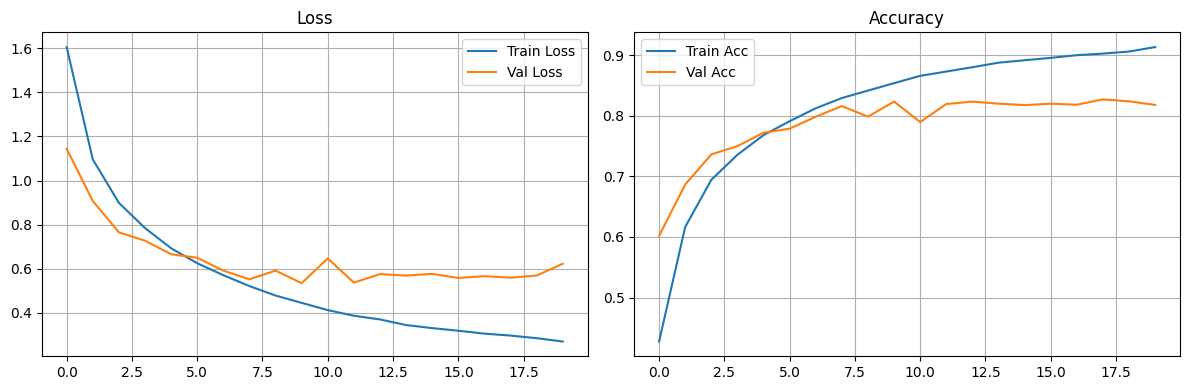

In [ ]:
history = trainer.history

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"],   label="Val Loss")
plt.title("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"],   label="Val Acc")
plt.title("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



## Test-set evaluation

/tmp/ipykernel_1922/1153188780.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


🏆 Test Loss: 0.6456 | Test Accuracy: 0.8057


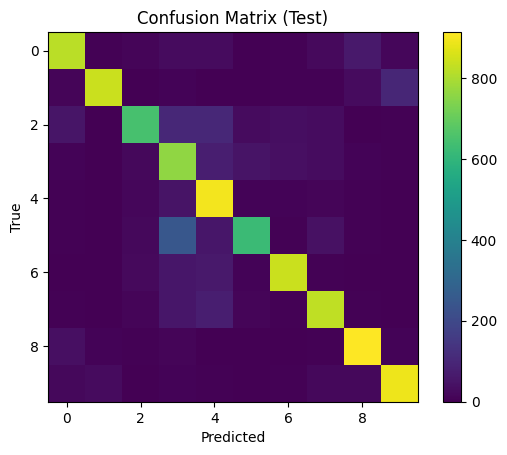

Classification report (Test):
              precision    recall  f1-score   support

           0     0.8452    0.8190    0.8319      1000
           1     0.9492    0.8410    0.8918      1000
           2     0.8502    0.6470    0.7348      1000
           3     0.5751    0.7620    0.6555      1000
           4     0.6879    0.8970    0.7786      1000
           5     0.8511    0.6230    0.7194      1000
           6     0.8841    0.8390    0.8610      1000
           7     0.8283    0.8250    0.8267      1000
           8     0.8712    0.9130    0.8916      1000
           9     0.8641    0.8900    0.8768      1000

    accuracy                         0.8056     10000
   macro avg     0.8206    0.8056    0.8068     10000
weighted avg     0.8206    0.8056    0.8068     10000



In [ ]:



# entire test result
test_loss, test_acc = trainer.evaluate(test_loader)
print(f"🏆 Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

# predictions
preds, targets = trainer.predict_all(test_loader)

# metrics
# 'average=macro' ensures this is the avg of the metric for all classes
test_precision = precision_score(targets, preds, average="macro")
test_recall    = recall_score(targets, preds, average="macro")
test_f1        = f1_score(targets, preds, average="macro")


# confusion matrix
cm = confusion_matrix(targets, preds)
plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix (Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.show()


# per-class report
print("Classification report (Test):")
print(classification_report(targets, preds, digits=4))

